# `fig:predictability` for the paper

Paper version of `three_channels_analysis/canal_2/unc_error_corr_vs_gene_predictability/classic.ipynb`, which is where the numbers are computed. This notebook draws them.

One figure, two rows, the same question. Grouping is by `(gene, slide)` throughout, so the error is ranked **across the spots of one gene**.

- **a)** one point per gene: its own prediction accuracy against its **absolute** controlled correlation, drawn as a low-alpha cloud, with the decile median on top.
- **b)** disjoint blocks of 100 genes along the predictability ordering. Each point is the donor-folded controlled correlation over one block.

**Both rows run worst-predicted on the left**, so a decline left to right means the same thing in both.
Output: `results/_analysis/figures_paper/`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))
from src.evaluation.benchmark_summary import donor_lopo_stats

# =============================== SETTINGS ====================================
RUN_ID      = "pr_classic3"
RESULTS     = PROJ / "results"
DATASETS    = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS      = "r75"
CANAL2      = "canal2_uncertainty"
LAMBDA_KEEP = 0.0
CASE        = "lin_pos"
# The heads kept on the gene axis. gene-homoscedastic: variance constant within the group,
# hence no rank correlation. Poisson: variance = mean, hence no partial. The NB with
# per-spot dispersion is measurable here, but EXCLUDED by choice.
MODELS      = ["heteroscedastic", "spot_homoscedastic",
               "negativebinomial_hetero_noanchor_cp"]
RANK_METRIC = "pearson"      # the metric of the predictability order (canal 1)
# The x axis of row a). True  : the donor cascade used everywhere else (mean over the slides
#                                WITHIN the donor, then over the donors) -- the SAME definition as
#                                the order of row b).
#                        False : one single mean over the test slides, weighted by n_spots.
ACCURACY_DONOR_CASCADE = True
NBINS       = 10             # deciles of row a), for the MEDIAN drawn over the scatter
BIN         = 100            # size of the DISJOINT blocks of row b)
FIGDIR      = PROJ / "results" / "_analysis" / "figures_paper"
# =============================================================================

N_PLUS_MIN, CONVENTION = 60, "v3_native_scale"
N_COL = {"lin_all": "n_plus_all", "lin_pos": "n_plus_pos", "log_pos": "n_plus_pos"}
MIN_SLIDES = 3               # a gene needs this many slides to have a value (row a)

MODEL_COLORS = {
    "heteroscedastic":                      "#ff7f0e",
    "spot_homoscedastic":                   "#2ca02c",
    "negativebinomial_hetero_noanchor_cp":  "#9467bd",
}
MODEL_LABELS = {
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

DONOR_MAP = yaml.safe_load((PROJ / "snake" / "config" / "donor_slide_map.yaml").read_text())


def slide_to_donor(ds):
    m = DONOR_MAP.get(ds) or {}
    return {sl: d for d, slides in m.items() for sl in slides}


def run_dir(ds, model):
    """The training RUN directory: it carries atoms.parquet, benchmark_summary.parquet and
    the canal2_uncertainty subdirectory."""
    base = RESULTS / ds / RUN_ID
    if not base.is_dir():
        return None
    for gs in sorted(p for p in base.iterdir() if p.is_dir()):
        m = gs / RADIUS / model
        if not m.is_dir():
            continue
        for leaf in [m] + sorted(m.glob("lambda_*")):
            if leaf.name.startswith("lambda_"):
                if not np.isclose(float(leaf.name[len("lambda_"):]), LAMBDA_KEEP):
                    continue
            if (leaf / CANAL2 / "summary.json").is_file():
                return leaf
    return None


PAIR, BENCH, RUNDIR, skipped = {}, {}, {}, []
for ds in DATASETS:
    for m in MODELS:
        rd = run_dir(ds, m)
        if rd is None:
            skipped.append((ds, m, "no canal2 run"))
            continue
        s = json.loads((rd / CANAL2 / "summary.json").read_text())
        if s.get("canal2_convention") != CONVENTION:
            skipped.append((ds, m, f"convention {s.get('canal2_convention')!r}"))
            continue
        f = rd / CANAL2 / "pair_partial.parquet"
        if f.is_file():
            PAIR[(ds, m)] = pd.read_parquet(f)
            RUNDIR[(ds, m)] = rd
        b = rd / "benchmark_summary.parquet"
        if b.is_file():
            BENCH[(ds, m)] = pd.read_parquet(b)
        else:
            skipped.append((ds, m, "no benchmark_summary.parquet"))

print(f"case = {CASE!r}   {len(PAIR)} pair_partial, {len(BENCH)} benchmark_summary "
      f"out of {len(DATASETS) * len(MODELS)} expected")
for ds, m, why in skipped:
    print(f"  (!) {ds:<12s} {m:<40s} {why}")

case = 'lin_pos'   9 pair_partial, 9 benchmark_summary out of 9 expected


In [2]:
# -- ROW a): the per-GENE value, folded over the slides, and the head's own accuracy ----------
def gene_level(frame):
    """One controlled value per gene: the slides folded with a weight equal to the group
    size, exactly the cascade of the canal 2 gene analysis."""
    col, ncol = f"r_partial_{CASE}", N_COL[CASE]
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna()]
    if d.empty:
        return None
    t = pd.DataFrame({"gene": d["gene"].to_numpy(),
                      "w":    d[ncol].to_numpy(float),
                      "wr":   d[ncol].to_numpy(float) * d[col].to_numpy(float)})
    g = t.groupby("gene", sort=True)
    out = pd.DataFrame({"r": g["wr"].sum() / g["w"].sum(), "n_slides": g.size()}).reset_index()
    return out[out["n_slides"] >= MIN_SLIDES]


def gene_accuracy(rd):
    """Per-gene accuracy on the TEST split, from the run's atoms.parquet.

    ACCURACY_DONOR_CASCADE = True : mean over the inner_split, then over the slides WITHIN the
    donor, then over the donors. One donor weighs as much as another, whatever its number
    of slides. This is exactly reduce_atoms_per_donor of src/evaluation/benchmark_summary.py,
    hence the same accuracy as the one that orders row b).

    False : one single mean over all the test slides, weighted by n_spots."""
    f = rd / "atoms.parquet"
    if not f.is_file():
        return None
    a = pd.read_parquet(f)
    met = next((c for c in ("pearson", "spearman") if c in a.columns), None)
    if met is None:
        return None
    a = a[(a["split"] == "test") & np.isfinite(a[met])]
    if a.empty:
        return None
    if ACCURACY_DONOR_CASCADE:
        assert "test_donor" in a.columns, f"no test_donor column in {f}"
        per_slide = a.groupby(["test_donor", "slide", "gene"])[met].mean()   # over the inner_split
        per_donor = per_slide.groupby(["test_donor", "gene"]).mean()         # over the slides
        return per_donor.groupby("gene").mean().rename("pred_corr").reset_index()
    t = pd.DataFrame({"gene": a["gene"].to_numpy(),
                      "w":    a["n_spots"].to_numpy(float),
                      "wm":   a["n_spots"].to_numpy(float) * a[met].to_numpy(float)})
    g = t.groupby("gene", sort=True)
    return pd.DataFrame({"pred_corr": g["wm"].sum() / g["w"].sum()}).reset_index()


PRED = {}
for (ds, m), frame in PAIR.items():
    gl, acc = gene_level(frame), gene_accuracy(RUNDIR[(ds, m)])
    if gl is None or acc is None:
        print(f"  (!) row a) impossible for {ds} / {m}")
        continue
    d = gl.merge(acc, on="gene")
    PRED[(ds, m)] = d[np.isfinite(d["pred_corr"]) & np.isfinite(d["r"])]


# -- ROW b): the predictability order, WORST PREDICTED FIRST ---------------------------------
# ONE single ranking per cohort: mean over the donors for each (model, gene), then
# intersection of the genes present in every head, then mean over the heads. The same rank
# therefore designates the same gene set on every curve.
ORDER = {}
for ds in DATASETS:
    pieces, shared = [], None
    for m in MODELS:
        b = BENCH.get((ds, m))
        if b is None or RANK_METRIC not in b.columns or "gene" not in b.columns:
            continue
        per_gene = b.groupby("gene")[RANK_METRIC].mean()
        shared = set(per_gene.index) if shared is None else (shared & set(per_gene.index))
        pieces.append(per_gene)
    if not pieces or not shared:
        print(f"  (!) {ds}: cannot build the predictability order")
        continue
    shared = sorted(shared)
    ORDER[ds] = (pd.concat([p.loc[shared] for p in pieces], axis=1).mean(axis=1)
                 .sort_values(ascending=True).index.to_numpy())    # ascending = worst first
    print(f"  {DATASET_LABELS.get(ds, ds):<22s} order over {len(ORDER[ds]):,} shared genes, "
          f"{len(pieces)} head(s) averaged")


def controlled_on(frame, ds, genes):
    """The controlled value folded over the donors, RESTRICTED to a gene set. Floored at
    N_PLUS_MIN, slides folded to (gene, donor) weighted by the group size, then a plain mean
    over the donor's genes. The restriction happens BEFORE that last mean."""
    col, ncol = f"r_partial_{CASE}", N_COL[CASE]
    if frame is None or col not in frame.columns:
        return None
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna() & frame["gene"].isin(genes)]
    if d.empty:
        return None
    s2d = slide_to_donor(ds)
    donor = d["slide"].map(lambda s: s2d.get(s, s))
    g = pd.DataFrame({"gene": d["gene"].to_numpy(), "donor": donor.to_numpy(),
                      "w": d[col].to_numpy() * d[ncol].to_numpy(),
                      "n": d[ncol].to_numpy()}).groupby(["gene", "donor"], as_index=False).sum()
    g["v"] = g["w"] / g["n"]
    pts = g.groupby("donor")["v"].mean().to_dict()
    if not pts:
        return None
    st = donor_lopo_stats(pts)
    return dict(mean=st["mean"], lo=st["ci95_mean"][0], hi=st["ci95_mean"][1], K=st["K"],
                n_genes=int(g["gene"].nunique()))


bin_rows = []
for ds in DATASETS:
    order = ORDER.get(ds)
    if order is None:
        continue
    for m in MODELS:
        frame = PAIR.get((ds, m))
        for s0 in range(0, len(order), BIN):
            block = order[s0:s0 + BIN]
            st = controlled_on(frame, ds, set(block))
            if st is not None:
                bin_rows.append(dict(dataset=ds, model=m, start=s0, size=len(block),
                                     center=s0 + len(block) / 2, **st))
TB = pd.DataFrame(bin_rows)
print(f"\nrow b): {len(TB)} blocks of {BIN} genes computed")

  Tumor Profiler         order over 3,000 shared genes, 3 head(s) averaged
  Kidney/Lung with TLS   order over 3,000 shared genes, 3 head(s) averaged
  NSCLC                  order over 3,000 shared genes, 3 head(s) averaged

row b): 270 blocks of 100 genes computed


## The paper figure — 2 rows x 3 cohorts, legend on the LEFT

`ROW_H` is the vertical knob. Row a is a scatter cloud, so it tolerates compaction less well than row b; if the cloud looks squashed, raise `ROW_H` rather than the total height.

legend strip = 0.203 of the width -> 2.27 in per panel


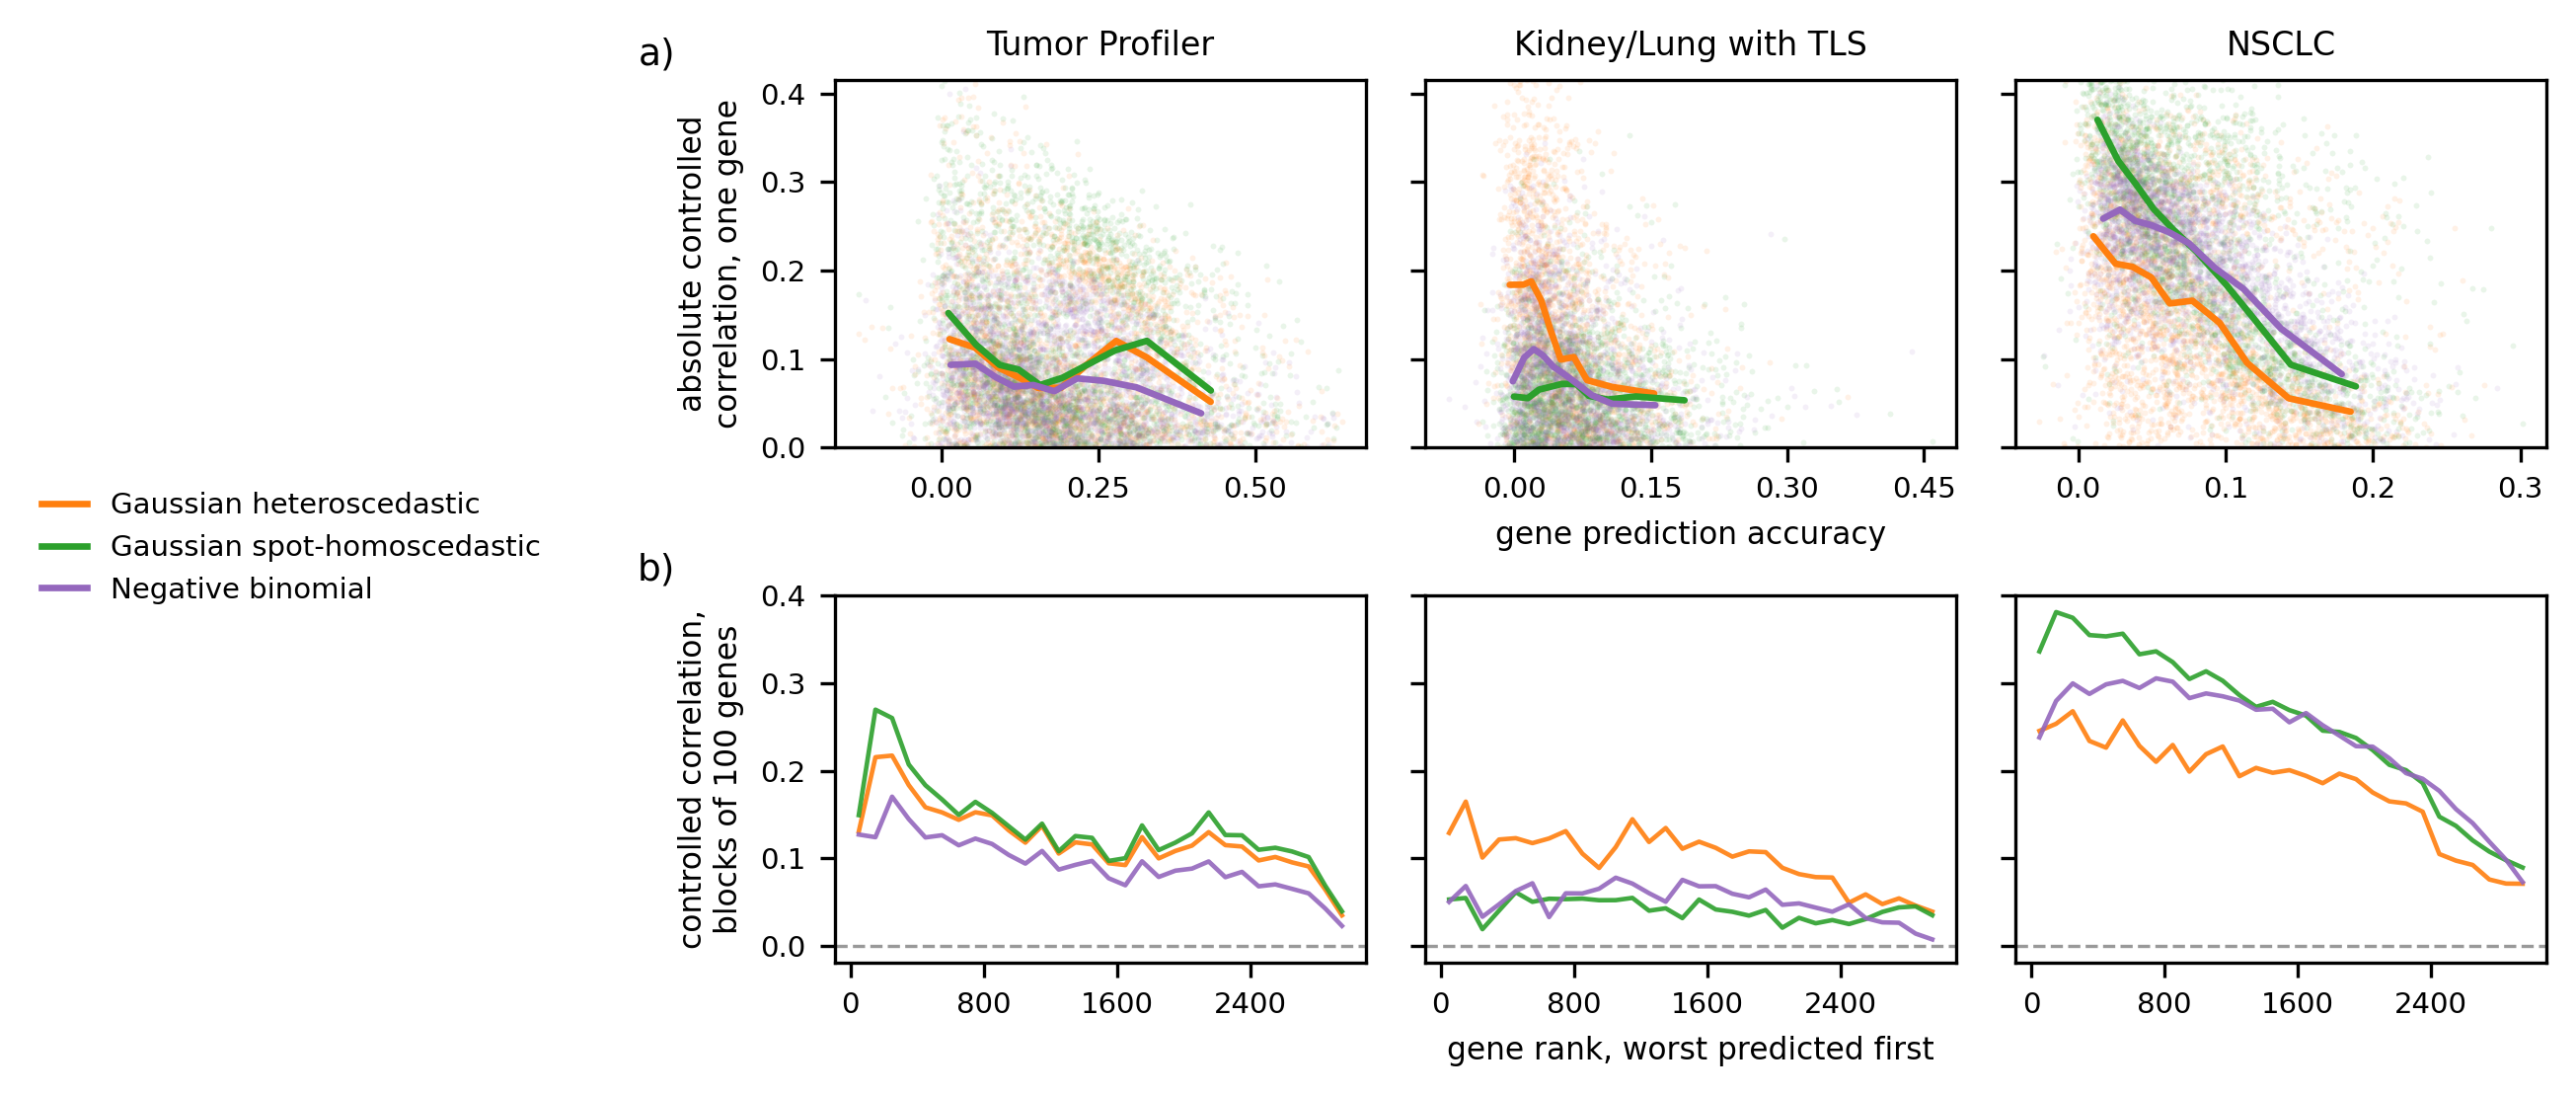

## FIGURE  fig_canal2_gene_axis_with_predictability_paper_donoracc_lin_pos_pr_classic3.pdf
## TITLE   The controlled error-uncertainty correlation against how well the gene is predicted
## CAPTION Error definition: |y - mu|, detected entries only (y > 0). Grouping: one group per gene
## CAPTION and slide, ranking the error across the spots of that gene. Colors are the heads.
## CAPTION Both rows put the WORST predicted genes on the left, so a decline left to right means
## CAPTION the correlation lives on the genes the model predicts worst.
## CAPTION a) one translucent point per gene, its own held-out accuracy against the absolute value
## CAPTION of its controlled correlation; the line is the median over deciles of that accuracy.
## CAPTION Absolute, because genes of opposite sign would otherwise cancel in the median; the
## CAPTION signed median travels in the printed table.
## CAPTION The view of a) is clipped at the 99th percentile, which leaves 1.0% of the
## CAPTION genes above 

In [3]:
FIGDIR.mkdir(parents=True, exist_ok=True)

# The scatter: one point per gene. rasterized=True keeps the PDF light (ten thousand or so
# points per panel would otherwise stay vector), the line and the text stay vector.
SCATTER_S     = 2.0
SCATTER_ALPHA = 0.1
YCLIP_Q       = 99.0   # row a)'s view is capped at this percentile, else the median flattens

COL_W         = 2.9    # width per cohort (width is the cheap axis)
ROW_H         = 1.9    # height per row (compacted for the paper)
LEGEND_FS     = 7
LEGEND_GUTTER = 0.015


def fig_show(fig, stem, title, caption):
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")


all_abs = np.concatenate([PRED[k]["r"].abs().to_numpy() for k in PRED]) if PRED else np.array([0.0])
y_hi = float(np.nanpercentile(all_abs, YCLIP_Q))
above = float((all_abs > y_hi).mean())

fig, axes = plt.subplots(2, len(DATASETS), figsize=(COL_W * len(DATASETS), 2 * ROW_H),
                         dpi=300, sharey="row")
axes = np.atleast_2d(axes)
drawn_a, drawn_b = [], []
for j, ds in enumerate(DATASETS):
    for m in MODELS:
        c = MODEL_COLORS[m]
        # a) one point per gene, plus the median per accuracy decile drawn over it
        d = PRED.get((ds, m))
        if d is not None:
            axes[0, j].scatter(d["pred_corr"], d["r"].abs(), s=SCATTER_S, alpha=SCATTER_ALPHA,
                               color=c, linewidths=0, rasterized=True, zorder=1)
            b = pd.qcut(d["pred_corr"], NBINS, labels=False, duplicates="drop")
            gb = d.assign(abs_r=d["r"].abs()).groupby(b, observed=True)
            x, y, s = (gb["pred_corr"].median().to_numpy(), gb["abs_r"].median().to_numpy(),
                       gb["r"].median().to_numpy())
            axes[0, j].plot(x, y, "-", lw=1.6, color=c, zorder=3,
                            path_effects=None, solid_capstyle="round")
            for xi, yi, si, ni in zip(x, y, s, gb.size().to_numpy()):
                drawn_a.append(dict(cohort=ds, head=m, acc_bin_median=xi, abs_assoc_median=yi,
                                    assoc_median=si, n_genes=int(ni)))
        # b) disjoint blocks of BIN genes along the predictability order
        t = TB[(TB["dataset"] == ds) & (TB["model"] == m)].sort_values("center")
        if not t.empty:
            axes[1, j].plot(t["center"], t["mean"], "-", color=c, lw=1.1, alpha=0.9)
            drawn_b.append(t.assign(head=m))
    axes[0, j].set_title(DATASET_LABELS[ds], fontsize=8)
    # ONE single axis label per row, under the MIDDLE column: three copies of the
    # same text would overlap from one column to the next.
    if j == len(DATASETS) // 2:
        axes[0, j].set_xlabel("gene prediction accuracy", fontsize=7.5)
        axes[1, j].set_xlabel("gene rank, worst predicted first", fontsize=7.5)
    axes[1, j].axhline(0.0, color="0.6", lw=0.8, ls="--", zorder=1)
    for i in (0, 1):
        axes[i, j].xaxis.set_major_locator(MaxNLocator(nbins=4))
        axes[i, j].tick_params(labelsize=7)
        if j == 0:
            axes[i, j].text(-0.30, 1.02, f"{'ab'[i]})", transform=axes[i, j].transAxes,
                            ha="right", va="bottom", fontsize=9)
axes[0, 0].set_ylim(0.0, y_hi)
axes[0, 0].set_ylabel("absolute controlled\ncorrelation, one gene", fontsize=7.5)
axes[1, 0].set_ylabel("controlled correlation,\nblocks of 100 genes", fontsize=7.5)

handles = [Line2D([], [], color=MODEL_COLORS[m], lw=1.6, label=MODEL_LABELS[m]) for m in MODELS
           if any(k[1] == m for k in PRED) or not TB[TB["model"] == m].empty]
leg = fig.legend(handles=handles, loc="center left", bbox_to_anchor=(0.0, 0.5),
                 ncol=1, frameon=False, fontsize=LEGEND_FS, handlelength=1.6)
fig.canvas.draw()
legend_w = leg.get_window_extent().width / fig.bbox.width
fig.tight_layout(rect=(legend_w + LEGEND_GUTTER, 0, 1, 1))
print(f"legend strip = {legend_w:.3f} of the width -> "
      f"{COL_W * len(DATASETS) * (1 - legend_w - LEGEND_GUTTER) / len(DATASETS):.2f} in per panel")

ACC_TAG  = "donoracc" if ACCURACY_DONOR_CASCADE else "slidew"
ACC_NOTE = ("Row a's accuracy is the donor cascade: mean over the slides of a donor, then over "
            "donors, the same definition that orders row b." if ACCURACY_DONOR_CASCADE else
            "Row a's accuracy is one average over the test slides, weighted by the number of "
            "spots, so a donor with more slides weighs more.")
fig_show(fig, FIGDIR / f"fig_canal2_gene_axis_with_predictability_paper_{ACC_TAG}_{CASE}_{RUN_ID}",
         "The controlled error-uncertainty correlation against how well the gene is predicted",
         ["Error definition: |y - mu|, detected entries only (y > 0). Grouping: one group per gene",
          "and slide, ranking the error across the spots of that gene. Colors are the heads.",
          "Both rows put the WORST predicted genes on the left, so a decline left to right means",
          "the correlation lives on the genes the model predicts worst.",
          "a) one translucent point per gene, its own held-out accuracy against the absolute value",
          "of its controlled correlation; the line is the median over deciles of that accuracy.",
          "Absolute, because genes of opposite sign would otherwise cancel in the median; the",
          "signed median travels in the printed table.",
          f"The view of a) is clipped at the {YCLIP_Q:g}th percentile, which leaves {above:.1%} of the",
          "genes above the frame; they are in the median but not drawn.",
          f"b) the same correlation over DISJOINT blocks of {BIN} genes along one ordering shared by",
          "all heads of the cohort, so a given rank means the same gene set on every curve. Each",
          "point is the mean over the block's genes, folded over held-out donors. No interval is",
          "drawn: a block rests on few genes and the intervals would hide the curves.",
          ACC_NOTE,
          "The two rows still differ in one way. Row a uses each head's own accuracy, row b one",
          "ordering averaged over heads. Row a is a per-gene value, row b a donor-folded mean.",
          "Genes are ranked by ACCURACY and the plotted quantity is a correlation with the ERROR,",
          "so no gene is selected on the quantity then reported on it. Accuracy and gene abundance",
          "are however strongly related, so this is not a pure predictability axis.",
          "Two heads are absent by construction: the gene-homoscedastic Gaussian has a variance",
          "constant inside the group, the Poisson has variance equal to its mean. The negative",
          "binomial with a dispersion per spot is measurable here but is left out."])

print()
print("=" * 96)
print("THE PRINTED TWIN - a) accuracy deciles (the line drawn over the scatter)")
print("=" * 96)
A = pd.DataFrame(drawn_a)
for ds in DATASETS:
    sub = A[A["cohort"] == ds]
    if sub.empty:
        continue
    print(f"\n--- {DATASET_LABELS[ds]} ---")
    print(sub.assign(head=sub["head"].map(MODEL_LABELS))
             .drop(columns="cohort").to_string(index=False,
                                               float_format=lambda x: f"{x:+.4f}"))

print()
print("=" * 96)
print(f"THE PRINTED TWIN - b) blocks of {BIN} genes (every third value)")
print("=" * 96)
B = pd.concat(drawn_b) if drawn_b else pd.DataFrame()
for ds in DATASETS:
    sub = B[B["dataset"] == ds] if not B.empty else B
    if sub.empty:
        continue
    print(f"\n--- {DATASET_LABELS[ds]} ---")
    piv = sub.pivot_table(index="head", columns="start", values="mean")
    piv = piv[[c for k, c in enumerate(piv.columns) if k % 3 == 0]]
    piv.index = [MODEL_LABELS.get(m, m) for m in piv.index]
    print(piv.round(4).to_string())

print()
print("-- the slope, read BOTH ways (negative = the correlation lives on the BADLY predicted genes) --")
print(f"  {'cohort':<22s} {'head':<30s} {'rho genes':>10s} {'rho deciles':>12s} {'rho blocks':>11s}")
agree = tot = 0
for ds in DATASETS:
    for m in MODELS:
        d = PRED.get((ds, m))
        a = A[(A["cohort"] == ds) & (A["head"] == m)] if not A.empty else A
        b = B[(B["dataset"] == ds) & (B["head"] == m)] if not B.empty else B
        if d is None or len(a) < 3 or len(b) < 3:
            continue
        rho_g = float(d["r"].abs().corr(d["pred_corr"], method="spearman"))
        rho_a = float(pd.Series(a["abs_assoc_median"].to_numpy()).corr(
            pd.Series(a["acc_bin_median"].to_numpy()), method="spearman"))
        rho_b = float(pd.Series(b["mean"].to_numpy()).corr(
            pd.Series(b["start"].to_numpy()), method="spearman"))
        tot += 1
        agree += (rho_g < 0) == (rho_b < 0)
        print(f"  {DATASET_LABELS[ds]:<22s} {MODEL_LABELS[m]:<30s} {rho_g:>+10.3f} "
              f"{rho_a:>+12.3f} {rho_b:>+11.3f}")
print(f"  -> the scatter and the blocks agree in sign on {agree}/{tot} pairs.")
print("     rho genes   : Spearman over ALL the genes, between the accuracy and the absolute value.")
print("     rho deciles : the same, over the ten points of the drawn line.")
print("     rho blocks  : Spearman between the block rank (worst first) and its value.")